# UNSUPERVISED PART : CVRIE

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

print('Numpy:', np.__version__)
print('Pandas:', pd.__version__)

Numpy: 2.4.2
Pandas: 3.0.1


In [ ]:

csv_path = "../Student_Dataset.csv"
dataframe = pd.read_csv(csv_path, encoding='utf-8-sig')
print(dataframe.head())
print(dataframe.shape)
print(dataframe.info())

                                                   1  \
2                                           0x000000   
3                                           0x000000   
4  A short sprint brought on a twinge in the midd...   
5                                           0x000000   
6  A sudden twist while reaching for a bag made o...   

  On uneven paths the heel feels wobbly side‑to‑side. Slanted pavements bring a quick aching shift under the ankle when I step.  
2  The feverish feeling eased, but I’m now breath...                                                                             
3  While working in the garden, I touched a metal...                                                                             
4                                                NaN                                                                             
5  I accidentally left my hand on a hot mug for a...                                                                             
6            

# EDA 


on peut constater que ce dataset contient 1010 lignes et 2 colonnes mais lorsque'on regarde le cvs de plus pret on peut voir des hexadecimal parfois :

C'est la conséquence des virgules dans les témoignages qui sont mal parser donc il faut corriger ca.

In [3]:
csv_path = "../Student_Dataset.csv"

tempdf = pd.read_csv(csv_path, encoding='utf-8-sig', header=None,
    names=['id', 'col2', 'col3'])

tempdf['text'] = np.where(tempdf['col2'] == '0x000000', tempdf['col3'], tempdf['col2'])
dataframe = tempdf[['id', 'text']]



print(dataframe.head())
print(dataframe.shape)
print(dataframe.info())
print('nombres elements louche dans le df: ', dataframe['text'].str.contains('0x000000').sum())


   id                                               text
0   1  On uneven paths the heel feels wobbly side‑to‑...
1   2  The feverish feeling eased, but I’m now breath...
2   3  While working in the garden, I touched a metal...
3   4  A short sprint brought on a twinge in the midd...
4   5  I accidentally left my hand on a hot mug for a...
(1011, 2)
<class 'pandas.DataFrame'>
RangeIndex: 1011 entries, 0 to 1010
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      1011 non-null   int64
 1   text    1011 non-null   str  
dtypes: int64(1), str(1)
memory usage: 15.9 KB
None
nombres elements louche dans le df:  0


# PreProcessing

Maitenant que nous avons enlever la 3 eme colonne aléatoire a cause du mauvais parsing du csv on peut commencer a s'occuper des stop words : Les motes qui n'ont pas d'utilité pour lié les différents témoiganges en eux :


## Les Stops Words

Comme les témopignages sont en anglais on peut utilisé la liste de stopwords contenue  avec sklearn

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
import re

vectorizer = TfidfVectorizer(stop_words='english')
stop_words = vectorizer.get_stop_words()

def remove_stop_words(text):
    tokens = text.lower().split()
    tokens = [t for t in tokens if t not in stop_words]
    return ' '.join(tokens)

import re

def remove_numbers(text):
    return re.sub(r'\d+\.?\d*\S*', '', text)



dataframe['clean_text'] = dataframe['text'].apply(remove_stop_words)
dataframe['clean_text'] = dataframe['clean_text'].apply(remove_numbers)

print(dataframe[['text', 'clean_text']].head(3))


                                                text  \
0  On uneven paths the heel feels wobbly side‑to‑...   
1  The feverish feeling eased, but I’m now breath...   
2  While working in the garden, I touched a metal...   

                                          clean_text  
0  uneven paths heel feels wobbly side‑to‑side. s...  
1  feverish feeling eased, i’m breathing faster d...  
2  working garden, touched metal grill stove. lef...  


ici on crée une nouvelle colonne clean_text car on veut grader la colonne original pour éventuels debug .

aussi on oublie pas d'enlever les nombres (et le petit float caché)

## Lemmatisation 

On constate que dans les note du kickoff on avait parler de TF idf qui est une mthode de vectoring que l'on doit utiliser pour cette exeercice : Cette methode permet de trandformer un mot en vecteur selon son importance dans le dataset -> si le mot est présent réguliérement dans tout les témoignage alors il n'tes que tres peu discriminant alors que a l'inverse si le mot est rare et exclusif a certain témoignages alors il va etre d'autant plus discriminant .

## Probleme de lemmatisation :

Dans ce contexte les vecteur sont precis pour chaque mot différents donc par exemple les mots burn et burning seront compté toatalement différents au yeyx des vecteurs donc il faut utiliser la lemmatisation pour que chaque mots de la meme famille sois normaliser exemple (Burning -> burn) de cette maminere chaque pharse traitatn de brulure peut imorte la conjugaison ect sera traiter avec le meme vecteur pour ce mot précis .

## La methode Spacy vs ntlk

- On aurait pu utiliser la methode fournit par ntlk cependant il faut préciser le type de mot donné pour que la fonction puisse bien focntionner alors que avec Spacy on n'tes pas obliger :

In [5]:
import spacy

nlp = spacy.load("en_core_web_sm")

def lemmatize(text):
    doc = nlp(text)
    return ' '.join([token.lemma_ for token in doc])

dataframe['clean_text'] = dataframe['clean_text'].apply(lemmatize)

print(dataframe[['text', 'clean_text']].head(3))


                                                text  \
0  On uneven paths the heel feels wobbly side‑to‑...   
1  The feverish feeling eased, but I’m now breath...   
2  While working in the garden, I touched a metal...   

                                          clean_text  
0  uneven path heel feel wobbly side‑to‑side . sl...  
1  feverish feeling ease , I ’m breathe fast dry ...  
2  work garden , touch metal grill stove . leave ...  


## Vectorisation

- on va dans cette partie tester les deux methode evoqué durant le kick off : TFIDF et bag of word 

TFIDF designe une methode pour étudié la fréquence d'un mot dans une phrase(tf) et globalement dans un data set(idf)

Bag of Word desinge une methode avec juste une pondération des mots mais pour gerer les mots qui ne sont vbraiment pas assez discriminants on peut utiliser les params de CountVectorizer(max_df=, min_df=) pour supprimer les mots trop occurnets .

## TFIDF

In [73]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(dataframe['clean_text'])


print("TF-IDF shape:", tfidf_matrix.shape)


TF-IDF shape: (1011, 1651)


## Bag Of Word

In [41]:
from sklearn.feature_extraction.text import CountVectorizer

bow_vectorizer = CountVectorizer(max_df=0.7, min_df=2)
bow_matrix = bow_vectorizer.fit_transform(dataframe['clean_text'])

print("BoW shape:", bow_matrix.shape)
print("Exemple de features:", bow_vectorizer.get_feature_names_out()[:10])


BoW shape: (1011, 1109)
Exemple de features: ['abdomen' 'able' 'accidentally' 'accompany' 'ache' 'achy' 'across'
 'active' 'activity' 'actual']


## DBSCAN vs K means

Les deux methode permettre de faire des clustring mais de différentes manières : 

DBscan permet de faire du clustering sans savoir le nombre de groupes a l'avance et ajuste automatiquement tandis que K means permet de faire du clusterinf avec un nombre de cluster donné en params.

Nous allons donc testé ces deux methodes sur nos matrice (BOW et TFIDF)

## Kmeans

In [78]:
from sklearn.cluster import KMeans

# mzthode appliqué a la matrice tfidf
kmeans_tfidf = KMeans(n_clusters=7, random_state=42, n_init=10)
kmeans_tfidf.fit(tfidf_matrix)

# methode appliqué a la matrice bow
kmeans_bow = KMeans(n_clusters=7, random_state=42, n_init=10)
kmeans_bow.fit(bow_matrix)

print("K-Means TF-IDF - taille des clusters:", np.bincount(kmeans_tfidf.labels_))
print("K-Means BoW    - taille des clusters:", np.bincount(kmeans_bow.labels_))


K-Means TF-IDF - taille des clusters: [306 120 235 132  54  81  83]
K-Means BoW    - taille des clusters: [ 95 179 335  72   5 261  64]


## DBSCANs

pour dbscan on a besoin de savoir l'ordre de grandeur des distance entre deux points pour savoir comment manipuler le parmas eps

In [56]:
from sklearn.metrics import pairwise_distances

distances = pairwise_distances(tfidf_matrix, metric='cosine')
print("Distance moyenne:", distances.mean())
print("Distance médiane:", np.median(distances))


Distance moyenne: 0.9726964640674246
Distance médiane: 1.0


In [58]:
from sklearn.metrics import pairwise_distances

distances_bow = pairwise_distances(bow_matrix, metric='cosine')
print("Distance moyenne:", distances_bow.mean())
print("Distance médiane:", np.median(distances_bow))


Distance moyenne: 0.9376570509027583
Distance médiane: 0.942833804952497


In [45]:
from sklearn.cluster import DBSCAN

# mzthode appliqué a la matrice tfidf
dbscan_tfidf = DBSCAN(eps=0.76, min_samples=4, metric='cosine')
dbscan_tfidf.fit(tfidf_matrix)

# methode appliqué a la matrice bow
dbscan_bow = DBSCAN(eps=0.66, min_samples=3, metric='cosine')
dbscan_bow.fit(bow_matrix)

print("DBSCAN TF-IDF - nb clusters:", len(set(dbscan_tfidf.labels_) - {-1}), "- bruit:", (dbscan_tfidf.labels_ == -1).sum())
print("DBSCAN BoW    - nb clusters:", len(set(dbscan_bow.labels_) - {-1}), "- bruit:", (dbscan_bow.labels_ == -1).sum())


DBSCAN TF-IDF - nb clusters: 4 - bruit: 170
DBSCAN BoW    - nb clusters: 3 - bruit: 193


## analyse des résultats :

- on constate une vol maximal pour les params choisit cependant trouver ce point d'équiloibre ne signifie pas que les cluster trouvé son bon : il fauit faire  tsne comme vue dans le kick off pour réduire les dimenssions 

In [53]:
from sklearn.decomposition import PCA

pca = PCA(n_components=10, random_state=42)
tfidf_pca = pca.fit_transform(tfidf_matrix.toarray())

pca_bow = PCA(n_components=10, random_state=42)
bow_pca = pca_bow.fit_transform(bow_matrix.toarray())

print("Variance expliquée:", pca.explained_variance_ratio_.sum())
print("Shape:", tfidf_pca.shape)
print("Shape:", bow_pca.shape)


Variance expliquée: 0.09712534117003685
Shape: (1011, 10)
Shape: (1011, 10)


In [60]:
distances_pca_eucl = pairwise_distances(tfidf_pca, metric='euclidean')
print("PCA euclidean - Distance moyenne:", distances_pca_eucl.mean())
print("PCA euclidean - Distance médiane:", np.median(distances_pca_eucl))


PCA euclidean - Distance moyenne: 0.4137376940579387
PCA euclidean - Distance médiane: 0.4125433175496854


In [71]:

dbscan = DBSCAN(eps=0.08, min_samples=4)
dbscan.fit(tfidf_pca)
n_clusters = len(set(dbscan.labels_) - {-1})
n_noise = (dbscan.labels_ == -1).sum()
print(f"eps={eps} → clusters: {n_clusters}, bruit: {n_noise}")


eps=0.42 → clusters: 13, bruit: 916


## version test pour < 500

In [51]:
for n in [5, 10, 20, 50, 100, 500]:
    pca_test = PCA(n_components=n, random_state=42)
    data_pca = pca_test.fit_transform(tfidf_matrix.toarray())
    km = KMeans(n_clusters=5, random_state=42, n_init=10)
    km.fit(data_pca)
    score = silhouette_score(data_pca, km.labels_)
    variance = pca_test.explained_variance_ratio_.sum()
    print(f"PCA {n}D → variance: {variance:.2%}, silhouette: {score:.4f}")


PCA 5D → variance: 5.94%, silhouette: 0.3372
PCA 10D → variance: 9.71%, silhouette: 0.2053
PCA 20D → variance: 15.39%, silhouette: 0.1172
PCA 50D → variance: 27.94%, silhouette: 0.0514
PCA 100D → variance: 43.02%, silhouette: 0.0380
PCA 500D → variance: 89.52%, silhouette: 0.0182


In [55]:
dbscan_pca = DBSCAN(eps=0.76, min_samples=4, metric='cosine')
dbscan_pca.fit(tfidf_pca)

bow_dbscan_pca = DBSCAN(eps=0.69, min_samples=3, metric='cosine')
bow_dbscan_pca.fit(bow_pca)

print("TFIDF DBSCAN PCA - nb clusters:", len(set(dbscan_pca.labels_) - {-1}), "- bruit:", (dbscan_pca.labels_ == -1).sum())
print("BOW DBSCAN PCA - nb clusters:", len(set(bow_dbscan_pca.labels_) - {-1}), "- bruit:", (bow_dbscan_pca.labels_ == -1).sum())


TFIDF DBSCAN PCA - nb clusters: 1 - bruit: 0
BOW DBSCAN PCA - nb clusters: 1 - bruit: 0


## conclusion
Conclusion sur methode dbscan et pca : Aucun résultats significatifs en utilisant ces methodes je pense que ces methode ne focntionne tout simplement pas sur ce type de données .

## Visualisation avec tSNE :

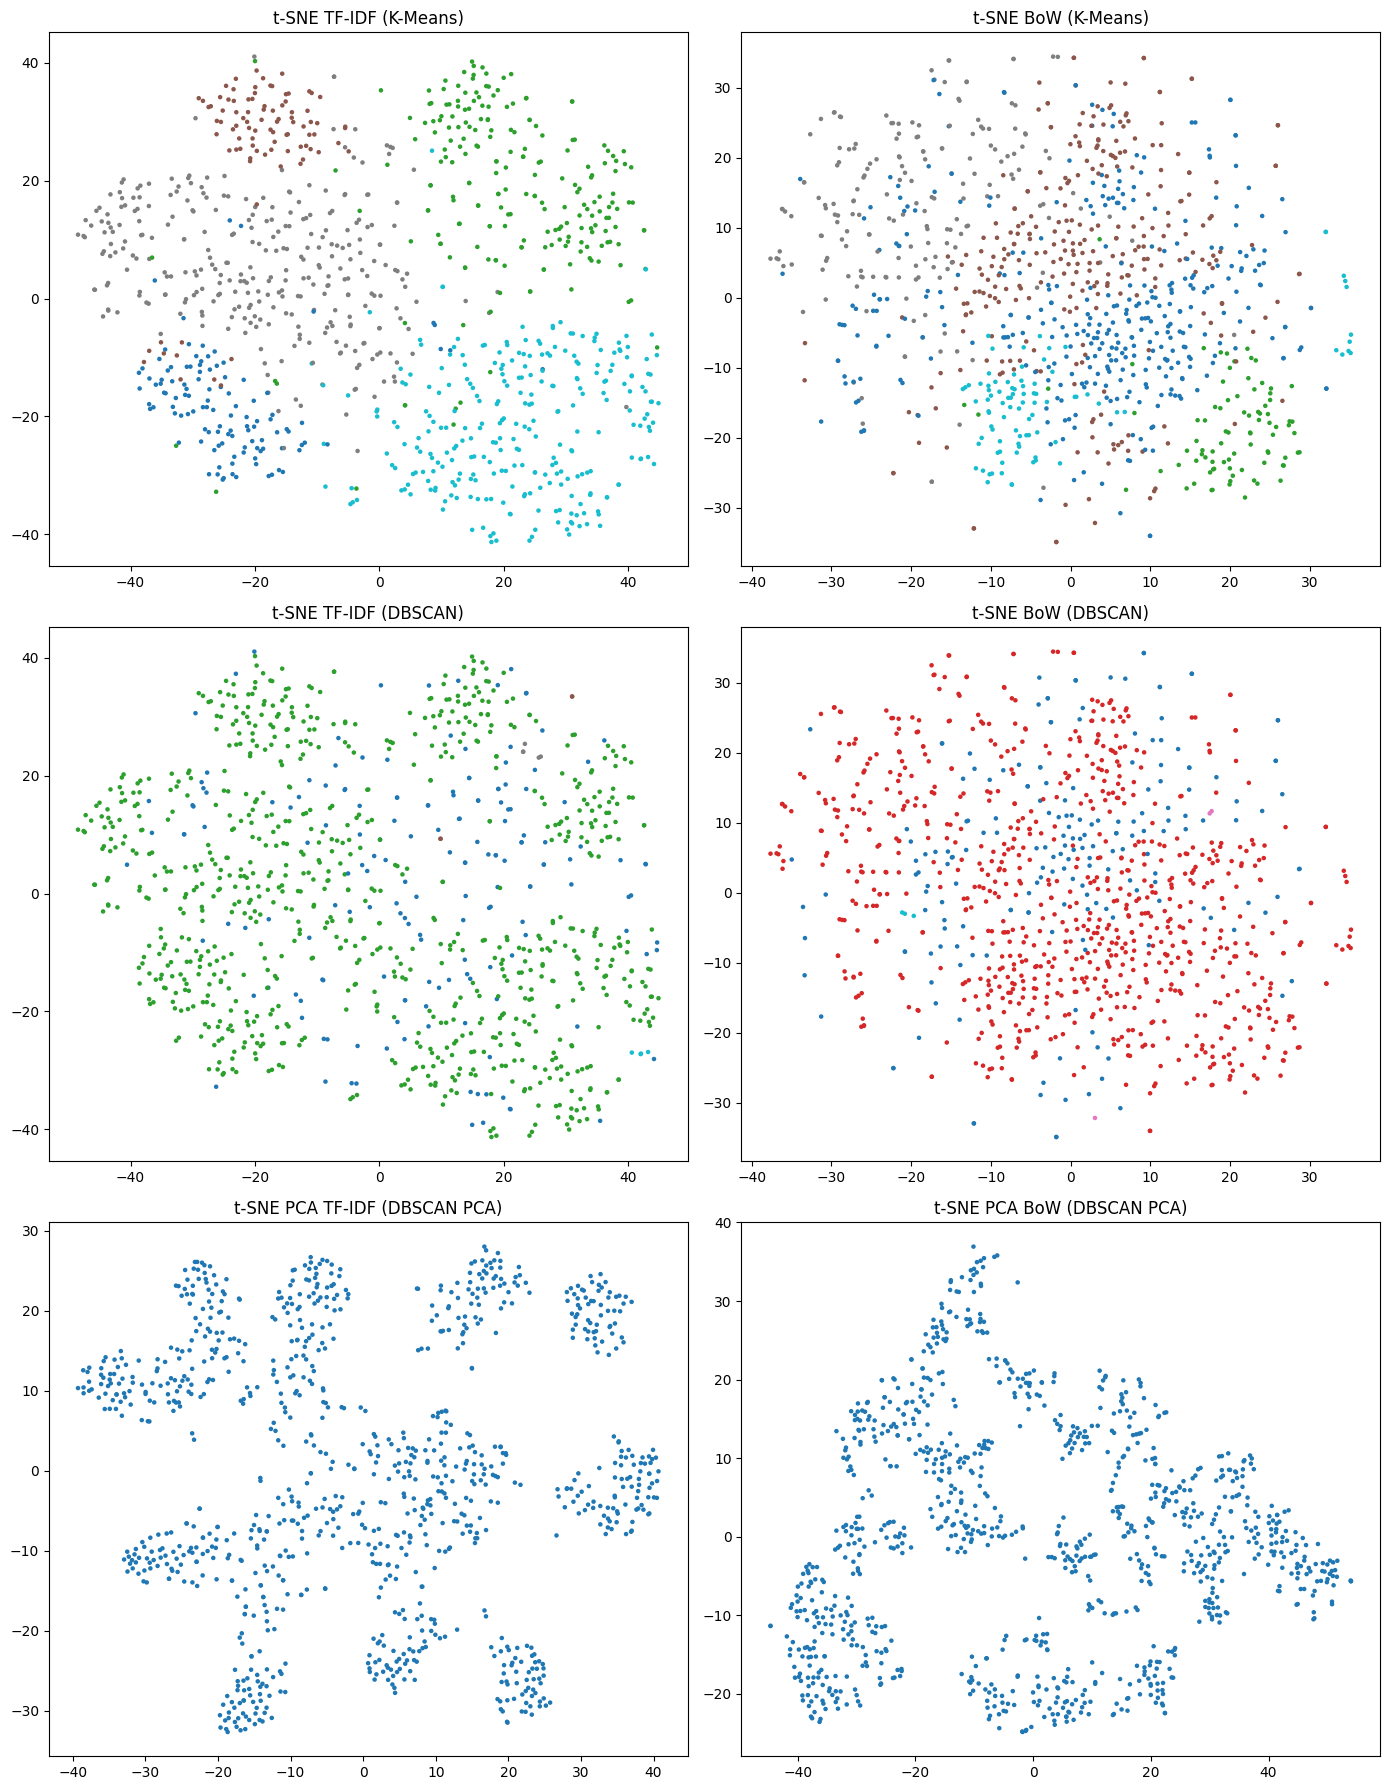

In [75]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# t-SNE sur TF-IDF
tsne_tfidf = TSNE(n_components=2, random_state=42, perplexity=30)
tfidf_tsne = tsne_tfidf.fit_transform(tfidf_matrix.toarray())

# t-SNE sur BoW
tsne_bow = TSNE(n_components=2, random_state=42, perplexity=30)
bow_tsne = tsne_bow.fit_transform(bow_matrix.toarray())

# t-SNE sur PCA TF-IDF
tsne_pca_tfidf = TSNE(n_components=2, random_state=42, perplexity=30)
tfidf_pca_tsne = tsne_pca_tfidf.fit_transform(tfidf_pca)

# t-SNE sur PCA BoW
tsne_pca_bow = TSNE(n_components=2, random_state=42, perplexity=30)
bow_pca_tsne = tsne_pca_bow.fit_transform(bow_pca)

fig, axes = plt.subplots(3, 2, figsize=(14, 18))

# K-Means
axes[0][0].scatter(tfidf_tsne[:, 0], tfidf_tsne[:, 1], c=kmeans_tfidf.labels_, cmap='tab10', s=5)
axes[0][0].set_title('t-SNE TF-IDF (K-Means)')

axes[0][1].scatter(bow_tsne[:, 0], bow_tsne[:, 1], c=kmeans_bow.labels_, cmap='tab10', s=5)
axes[0][1].set_title('t-SNE BoW (K-Means)')

# DBSCAN
axes[1][0].scatter(tfidf_tsne[:, 0], tfidf_tsne[:, 1], c=dbscan_tfidf.labels_, cmap='tab10', s=5)
axes[1][0].set_title('t-SNE TF-IDF (DBSCAN)')

axes[1][1].scatter(bow_tsne[:, 0], bow_tsne[:, 1], c=dbscan_bow.labels_, cmap='tab10', s=5)
axes[1][1].set_title('t-SNE BoW (DBSCAN)')

# DBSCAN PCA
axes[2][0].scatter(tfidf_pca_tsne[:, 0], tfidf_pca_tsne[:, 1], c=dbscan_pca.labels_, cmap='tab10', s=5)
axes[2][0].set_title('t-SNE PCA TF-IDF (DBSCAN PCA)')

axes[2][1].scatter(bow_pca_tsne[:, 0], bow_pca_tsne[:, 1], c=bow_dbscan_pca.labels_, cmap='tab10', s=5)
axes[2][1].set_title('t-SNE PCA BoW (DBSCAN PCA)')

plt.tight_layout()
plt.show()



In [49]:
print("Silhouette t-SNE TF-IDF (K-Means):", silhouette_score(tfidf_tsne, kmeans_tfidf.labels_))


Silhouette t-SNE TF-IDF (K-Means): 0.3021569550037384


In [50]:
from sklearn.cluster import KMeans

km_pca = KMeans(n_clusters=5, random_state=42, n_init=10)
km_pca.fit(tfidf_pca)

print("Silhouette PCA TF-IDF:", silhouette_score(tfidf_pca, km_pca.labels_))


Silhouette PCA TF-IDF: 0.018241405004700856


On con,state donc qu'un set de methode focntionne mieuyx de qu'autre : 

on dirait que dbscan meme avec pca n'tes pas adapté au texte vectoriser en raison de l'uniformité des données .
Le pca aurait pu amiliorer les résultats si le probleme etait d'ordre dimensionnel cependant ici ce n'rtes pas le probleme comme on peut le voir au dessus.

# Metrics Interne

-cette outil nous permet au lieu d'estimer les cluster avec nos yeux on peut constater les cluser a l'aide du silhouette score  : 
Il va mesurer si chauq epoint est pret de son cluster et loin des autres en gros .



In [38]:
from sklearn.metrics import silhouette_score

# K-Means
print("=== Silhouette Score ===")
print("K-Means TF-IDF:", silhouette_score(tfidf_matrix, kmeans_tfidf.labels_))
print("K-Means BoW:", silhouette_score(bow_matrix, kmeans_bow.labels_))

# DBSCAN (on exclut le bruit pour le calcul)
mask_tfidf = dbscan_tfidf.labels_ != -1
mask_bow = dbscan_bow.labels_ != -1
print("DBSCAN TF-IDF:", silhouette_score(tfidf_matrix[mask_tfidf], dbscan_tfidf.labels_[mask_tfidf]))
print("DBSCAN BoW:", silhouette_score(bow_matrix[mask_bow], dbscan_bow.labels_[mask_bow]))



=== Silhouette Score ===
K-Means TF-IDF: 0.011484599514266681
K-Means BoW: 0.02516762055257549
DBSCAN TF-IDF: -0.005215428928618881
DBSCAN BoW: -0.002390354158218578


# test avec la methode du coude :

- Il faut trouver les meilleurs paramaetre pour kmeans donc tester tout les n_cluster pour savoir le nombre de cluster optimal par le biais de sklearn plsutot qu'avec nos yeux :


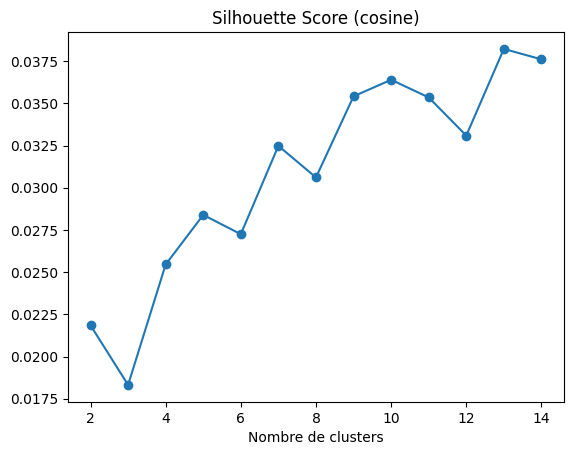

In [26]:
silhouettes_cosine = []
K = range(2, 15)

for k in K:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(tfidf_matrix)
    silhouettes_cosine.append(silhouette_score(tfidf_matrix, km.labels_, metric='cosine'))

plt.plot(K, silhouettes_cosine, 'o-')
plt.title('Silhouette Score (cosine)')
plt.xlabel('Nombre de clusters')
plt.show()



In [25]:
print("=== Silhouette Score (cosine) ===")
print("K-Means TF-IDF:", silhouette_score(tfidf_matrix, kmeans_tfidf.labels_, metric='cosine'))
print("K-Means BoW:", silhouette_score(bow_matrix, kmeans_bow.labels_, metric='cosine'))


=== Silhouette Score (cosine) ===
K-Means TF-IDF: 0.025453047997519376
K-Means BoW: 0.034004912860610914


# FOCUS sur TFIDF kmeans :

- ici nous allons focus sur la meilleurs tantative que nous avons : TFIDF kmeans 

In [76]:
for i in range(5):
    print(f"\n=== Cluster {i} ({(kmeans_tfidf.labels_ == i).sum()} phrases) ===")
    mask = kmeans_tfidf.labels_ == i
    for text in dataframe[mask]['text'].head(5):
        print(f"  - {text[:100]}...")



=== Cluster 0 (114 phrases) ===
  - Since last week, my right ear has been aching and I noticed a slight fluid drainage. I feel a buzzin...
  - My right ear hurts like a stone in the middle. The pain is stronger when I drive. I had a flu 5 days...
  - I keep waking up at night because my ear hurts so badly. I also feel like something is blocking my e...
  - I feel like my ear is clogged and I can hear faint noises. I have a slight fever and feel tired....
  - I start feeling a dull pressure in my head before I’m able to sleep. The pain flares up when I eat s...

=== Cluster 1 (219 phrases) ===
  - While working in the garden, I touched a metal grill that had been on the stove. My left forearm has...
  - I accidentally left my hand on a hot mug for a minute. It now feels very tender, and there's a small...
  - During a birthday party, a hot beverage was knocked onto my back. The area is red, tender, and a sma...
  - I noticed a rash on my forearms after handling a new brand of sunscree

COnstatation : 

On peuty voir que les cluster sont en partie représentatifs meme si il existe de spetites erreurs et exeception et meme un cluster un peu mélanger mais c'tes deja un résultatts 

-le cluster 0 représente en partie les oreille ,
le 1 = peau + brulure
le 2 = rhume sinus 
le 3 = mélanger 
le 4 =  douleurs muscles ou os sur membres ?

## Test avec 7 cluster pour kmeans :


In [77]:
kmeans_tfidf_7 = KMeans(n_clusters=7, random_state=42, n_init=10)
kmeans_tfidf_7.fit(tfidf_matrix)

for i in range(7):
    print(f"\n=== Cluster {i} ({(kmeans_tfidf_7.labels_ == i).sum()} phrases) ===")
    mask = kmeans_tfidf_7.labels_ == i
    for text in dataframe[mask]['text'].head(3):
        print(f"  - {text[:100]}...")



=== Cluster 0 (306 phrases) ===
  - On uneven paths the heel feels wobbly side‑to‑side. Slanted pavements bring a quick aching shift und...
  - A short sprint brought on a twinge in the middle of the back of my thigh. It’s tender along a band a...
  - A sudden twist while reaching for a bag made one side of my lower back feel ‘switched off’ and sore....

=== Cluster 1 (120 phrases) ===
  - Since last week, my right ear has been aching and I noticed a slight fluid drainage. I feel a buzzin...
  - My right ear hurts like a stone in the middle. The pain is stronger when I drive. I had a flu 5 days...
  - My right ear hurts when I swallow, and I feel pressure when I sit in the car. It’s been a few days s...

=== Cluster 2 (235 phrases) ===
  - Since I lost 20 pounds, my headaches have lessened, but I still feel lightheaded when I stand up. I ...
  - I feel an unexplained pressure behind my eyes and a dull ache in my neck. It’s mild but persistent....
  - My eyelids squeeze shut in little 

Je constate que si je voyais des disparité au niveaui de la repartition par cluster je pensais que c'etait signe d'erreur masi enfete il peut tout simplement exister plus de témoignage sur un theme que d'autre ce qui explique pouruqoi kmeans 7 et moins uniforme que 5 cluster et pourtant reflete plus la vrais classification du dataset.

En testant les cluster un a un on peut observer les changements dans la repartition :

## Test avec 8 cluster 

In [79]:
kmeans_tfidf_8 = KMeans(n_clusters=8, random_state=42, n_init=10)
kmeans_tfidf_8.fit(tfidf_matrix)

for i in range(8):
    print(f"\n=== Cluster {i} ({(kmeans_tfidf_8.labels_ == i).sum()} phrases) ===")
    mask = kmeans_tfidf_8.labels_ == i
    for text in dataframe[mask]['text'].head(3):
        print(f"  - {text[:100]}...")



=== Cluster 0 (126 phrases) ===
  - I feel an unexplained pressure behind my eyes and a dull ache in my neck. It’s mild but persistent....
  - My eyelids squeeze shut in little bursts when I’m reading or in bright light. I have to blink hard t...
  - I noticed my hands have started to feel numb and tingly, especially after standing for a while. I al...

=== Cluster 1 (234 phrases) ===
  - On uneven paths the heel feels wobbly side‑to‑side. Slanted pavements bring a quick aching shift und...
  - A short sprint brought on a twinge in the middle of the back of my thigh. It’s tender along a band a...
  - A sudden twist while reaching for a bag made one side of my lower back feel ‘switched off’ and sore....

=== Cluster 2 (67 phrases) ===
  - Since last week, my right ear has been aching and I noticed a slight fluid drainage. I feel a buzzin...
  - My right ear hurts like a stone in the middle. The pain is stronger when I drive. I had a flu 5 days...
  - My right ear hurts when I swallow, 

Ce dernier est encore mieux car il permet de séparé mieux les probleme de rhume et les problme e fievre + maladie respiratoire cependant le cluster contenant les témoignage de brulyure c'tes anormalment aggrandit donc nous allons verifié la qualité du cluster  :

In [80]:
mask = kmeans_tfidf_8.labels_ == 5
for text in dataframe[mask]['text'].head(15):
    print(f"  - {text[:120]}...")
    print()


  - While working in the garden, I touched a metal grill that had been on the stove. My left forearm has a burning itch and ...

  - I accidentally left my hand on a hot mug for a minute. It now feels very tender, and there's a small blister....

  - During a birthday party, a hot beverage was knocked onto my back. The area is red, tender, and a small blister is visibl...

  - On the sole, a painful spot feels like stepping on a stone. The surface is rough with tiny dark dots...

  - At the base of my thumb toward the wrist there’s a tiny sore spot. Pinching or pressing a jar lid sets it off for a whil...

  - A metal pot fell on my thigh. The skin is red and blistered, and it’s uncomfortable when I walk....

  - I forgot my hand inside a boiling pot while making soup. The left forearm is now bright red, itching, and a small bliste...

  - Between my toes the skin is itchy, cracked, and peels. After workouts the area stings and smells stronger...

  - I was painting a fence and acciden

Au final on voit que passer a 8 cluster a malheusement profondement dégradé les témoignages liées aux brulures qui sont maitenant mélanger avec de la dermato et du musculosqueltique , maitenant on peut tester 9 pour voir si cela sépare mieux la partie brulure mélangé :

In [81]:
kmeans_tfidf_9 = KMeans(n_clusters=9, random_state=42, n_init=10)
kmeans_tfidf_9.fit(tfidf_matrix)

for i in range(9):
    print(f"\n=== Cluster {i} ({(kmeans_tfidf_9.labels_ == i).sum()} phrases) ===")
    mask = kmeans_tfidf_9.labels_ == i
    for text in dataframe[mask]['text'].head(3):
        print(f"  - {text[:100]}...")



=== Cluster 0 (137 phrases) ===
  - On uneven paths the heel feels wobbly side‑to‑side. Slanted pavements bring a quick aching shift und...
  - A sudden twist while reaching for a bag made one side of my lower back feel ‘switched off’ and sore....
  - There’s a small sore area on the top of my foot that flares when I push off while walking. Tight sho...

=== Cluster 1 (62 phrases) ===
  - Since last week, my right ear has been aching and I noticed a slight fluid drainage. I feel a buzzin...
  - My right ear hurts like a stone in the middle. The pain is stronger when I drive. I had a flu 5 days...
  - My right ear hurts when I swallow, and I feel pressure when I sit in the car. It’s been a few days s...

=== Cluster 2 (189 phrases) ===
  - While working in the garden, I touched a metal grill that had been on the stove. My left forearm has...
  - I accidentally left my hand on a hot mug for a minute. It now feels very tender, and there's a small...
  - During a birthday party, a hot bev

## Ouverture :

-Possibilité peut etre de faire un kmeans sur uniquement le cluster melanger pour faire du sous clustering (un espce de fine tuning du clustering)